<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/244107020147-mobile-course/blob/main/UTS_Klastering/Kmeans_Cosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **KUIS & UTS MATA KULIAH PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **K-MEANS COSINE DISTANCE**


In [1]:
# import library & setting
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = "/content/drive/MyDrive/UTSML2026/outputKmeans"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("[INFO] Library berhasil diinstall.")
print(f"[INFO] Folder output: '{OUTPUT_DIR}' | Random state: {RANDOM_STATE}")

Mounted at /content/drive
[INFO] Library berhasil diinstall.
[INFO] Folder output: '/content/drive/MyDrive/UTSML2026/outputKmeans' | Random state: 42


In [2]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/UTSML2026/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [3]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw['Diabetes_binary'].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [4]:
# preprocessing
LABEL = 'Diabetes_binary'          # label sudah 0 dan 1
FITUR_DIBUANG = ['Income','CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")
print(f"Sebaran kelas awal: {df[LABEL].value_counts().sort_index().to_dict()}")

df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur       : {df.shape[1]} kolom (termasuk label)")

n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat    : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(f"Sebaran kelas akhir       : {df[LABEL].value_counts().sort_index().to_dict()}")

y_label = df[LABEL].copy()   # label hanya untuk pembanding, tidak dipakai klastering
df_features = df.drop(columns=[LABEL]).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

scaler = StandardScaler()
X_std = scaler.fit_transform(df_features.values)
X_norm = Normalizer(norm='l2').fit_transform(X_std)   # proyeksi ke unit hypersphere ||x|| = 1
print(f"Bentuk data siap klaster: {X_norm.shape}")
print(f"Cek norma L2 tiga baris pertama (harus 1): {np.linalg.norm(X_norm[:3], axis=1)}")

Data awal: 70692 baris x 22 kolom
Sebaran kelas awal: {0.0: 35346, 1.0: 35346}
Setelah buang fitur       : 16 kolom (termasuk label)
Setelah hapus duplikat    : 63197 baris (terbuang 7495)
Sebaran kelas akhir       : {0.0: 29885, 1.0: 33312}
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster: (63197, 15)
Cek norma L2 tiga baris pertama (harus 1): [1. 1. 1.]


In [5]:
# Model Kmeans
class KMeansCosine:
    """K-Means dengan jarak Cosine. Centroid = rata-rata vektor yang dinormalisasi lagi ke bola satuan."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='cosine', n_jobs=-1)

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]

        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])

        centroids = np.array(centroids)
        norms = np.linalg.norm(centroids, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        return centroids / norms

    def fit(self, X):
        start_time = time.perf_counter()

        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        X_calc = X / norms

        self.centroids = self._init_centroids(X_calc)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X_calc, self.centroids)
            labels = np.argmin(dists, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X_calc[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X_calc[rng.randint(len(X_calc))]
                else:
                    mean_vec = np.mean(cluster_pts, axis=0)
                    norm = np.linalg.norm(mean_vec)
                    new_centroids[k] = mean_vec / (norm if norm > 0 else 1.0)

            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels

            if shift < self.tol:
                break

        final_dists = self._compute_distance(X_calc, self.centroids)
        assigned_dists = final_dists[np.arange(len(X_calc)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

print("[INFO] Kelas KMeansCosine berhasil diinisialisasi.")

[INFO] Kelas KMeansCosine berhasil diinisialisasi.


  k = 1  | Cosine Inertia = 58,841.1 | iterasi = 2
  k = 2  | Cosine Inertia = 40,119.8 | iterasi = 18
  k = 3  | Cosine Inertia = 35,590.4 | iterasi = 18
  k = 4  | Cosine Inertia = 32,743.1 | iterasi = 23
  k = 5  | Cosine Inertia = 30,467.0 | iterasi = 27
  k = 6  | Cosine Inertia = 28,529.0 | iterasi = 50
  k = 7  | Cosine Inertia = 27,116.0 | iterasi = 47
  k = 8  | Cosine Inertia = 25,749.8 | iterasi = 38
  k = 9  | Cosine Inertia = 25,060.5 | iterasi = 54
  k = 10 | Cosine Inertia = 23,860.9 | iterasi = 74
[INFO] k dikunci = 4 (sama untuk semua metrik jarak)
[ELBOW] Jumlah klaster optimal terdeteksi: k = 4
[SIMPAN] Grafik Elbow disimpan ke: '/content/drive/MyDrive/UTSML2026/outputKmeans/elbow_cosine.png'


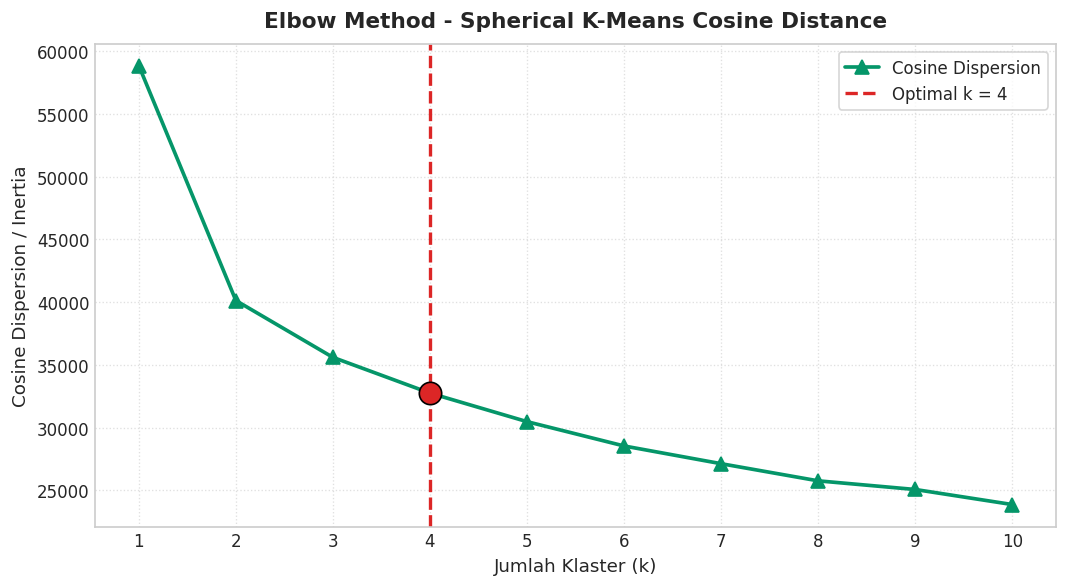

In [6]:
# Elbow Method Cosine
k_range = list(range(1, 11))
inertia_cosine = []

for k in k_range:
    km = KMeansCosine(n_clusters=k, max_iter=200, random_state=RANDOM_STATE)
    km.fit(X_norm)
    inertia_cosine.append(km.inertia_)
    print(f"  k = {k:<2} | Cosine Inertia = {km.inertia_:,.1f} | iterasi = {km.n_iter_}")

def find_elbow_point(k_vals, inertias):
    p1 = np.array([k_vals[0], inertias[0]])
    p2 = np.array([k_vals[-1], inertias[-1]])
    line_vec = p2 - p1
    line_unit = line_vec / np.linalg.norm(line_vec)
    dists = [
        np.linalg.norm((np.array([k, s]) - p1) - np.dot(np.array([k, s]) - p1, line_unit) * line_unit)
        for k, s in zip(k_vals, inertias)
    ]
    return k_vals[int(np.argmax(dists))]

optimal_k = 4   # disamakan dengan Euclidean & Manhattan supaya apple to apple
print(f"[INFO] k dikunci = {optimal_k} (sama untuk semua metrik jarak)")
print(f"[ELBOW] Jumlah klaster optimal terdeteksi: k = {optimal_k}")

plt.figure(figsize=(9, 5))
plt.plot(k_range, inertia_cosine, marker='^', markersize=8, linewidth=2.2, color='#059669', label='Cosine Dispersion')
plt.axvline(x=optimal_k, color='#DC2626', linestyle='--', linewidth=2, label=f'Optimal k = {optimal_k}')
plt.scatter([optimal_k], [inertia_cosine[optimal_k - 1]], color='#DC2626', s=180, zorder=5, edgecolor='black')
plt.title('Elbow Method - Spherical K-Means Cosine Distance', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Jumlah Klaster (k)', fontsize=11)
plt.ylabel('Cosine Dispersion / Inertia', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_cosine.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SIMPAN] Grafik Elbow disimpan ke: '{elbow_path}'")
plt.show()

In [7]:
# Klastering Final, evaluasi dan implementasi hasil
model_cosine = KMeansCosine(n_clusters=optimal_k, max_iter=300, tol=1e-4, random_state=RANDOM_STATE)
model_cosine.fit(X_norm)
labels = model_cosine.labels_

sil_score = float(silhouette_score(X_norm, labels, metric='cosine', sample_size=10000, random_state=RANDOM_STATE))
db_score = float(davies_bouldin_score(X_norm, labels))
ch_score = float(calinski_harabasz_score(X_norm, labels))

eval_df = pd.DataFrame([{
    'Distance Metric': 'Cosine Distance (Spherical)',
    'Optimal k': optimal_k,
    'Jumlah Data': X_norm.shape[0],
    'Jumlah Fitur': X_norm.shape[1],
    'Silhouette Score (↑)': round(sil_score, 4),
    'Davies–Bouldin Index (↓)': round(db_score, 4),
    'Calinski–Harabasz Index (↑)': round(ch_score, 2),
    'Execution Time (s) (↓)': round(model_cosine.execution_time_, 5),
    'Iterations (↓)': model_cosine.n_iter_,
    'Objective Value (Inertia) (↓)': round(model_cosine.inertia_, 2)
}])

print("\n" + "=" * 80)
print("TABEL EVALUASI K-MEANS COSINE")
print("=" * 80)
print(eval_df.to_string(index=False))
print("=" * 80)

df_clustered = df_features.copy()
df_clustered[LABEL] = y_label.values
df_clustered['Cluster_Cosine'] = labels

profil = df_clustered.groupby('Cluster_Cosine').mean().round(3)
profil['Jumlah Data'] = df_clustered['Cluster_Cosine'].value_counts().sort_index()
profil['% Diabetes'] = (df_clustered.groupby('Cluster_Cosine')[LABEL].apply(lambda s: (s == 1).mean() * 100)).round(2)

excel_path = os.path.join(OUTPUT_DIR, "evaluasi_kmeans_cosine.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    eval_df.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    profil.to_excel(writer, sheet_name='Profil_Klaster')
print(f"[SIMPAN] Evaluasi & profil klaster disimpan ke: '{excel_path}'")

csv_path = os.path.join(OUTPUT_DIR, "data_terklaster_cosine.csv")
df_clustered.to_csv(csv_path, index=False)
print(f"[SIMPAN] Data terklaster disimpan ke: '{csv_path}'")


TABEL EVALUASI K-MEANS COSINE
            Distance Metric  Optimal k  Jumlah Data  Jumlah Fitur  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)  Iterations (↓)  Objective Value (Inertia) (↓)
Cosine Distance (Spherical)          4        63197            15                0.1982                    2.5052                      6258.32                 0.80107              23                        32743.1
[SIMPAN] Evaluasi & profil klaster disimpan ke: '/content/drive/MyDrive/UTSML2026/outputKmeans/evaluasi_kmeans_cosine.xlsx'
[SIMPAN] Data terklaster disimpan ke: '/content/drive/MyDrive/UTSML2026/outputKmeans/data_terklaster_cosine.csv'


In [8]:
# Profil Tiap Klaster
profil

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_binary,Jumlah Data,% Diabetes
Cluster_Cosine,,,,,,,,,,,,,,,,,,
0,0.814,0.727,33.106,0.595,0.166,0.349,0.450,0.570,0.797,3.960,8.793,16.880,0.793,0.388,9.486,0.761,18677,76.10
1,0.496,0.480,28.617,1.000,0.030,0.103,0.796,0.635,1.000,2.497,2.384,1.938,0.046,0.532,8.533,0.427,14980,42.74
2,0.448,0.431,28.939,0.000,0.020,0.057,0.819,0.689,1.000,2.393,2.065,1.911,0.043,0.415,7.925,0.386,18749,38.62
3,0.558,0.509,29.769,0.459,0.042,0.101,0.646,0.386,0.000,2.713,2.383,2.649,0.132,0.539,8.464,0.506,10791,50.55


[SIMPAN] Grafik pemetaan klaster disimpan ke: '/content/drive/MyDrive/UTSML2026/outputKmeans/cluster_cosine.png'


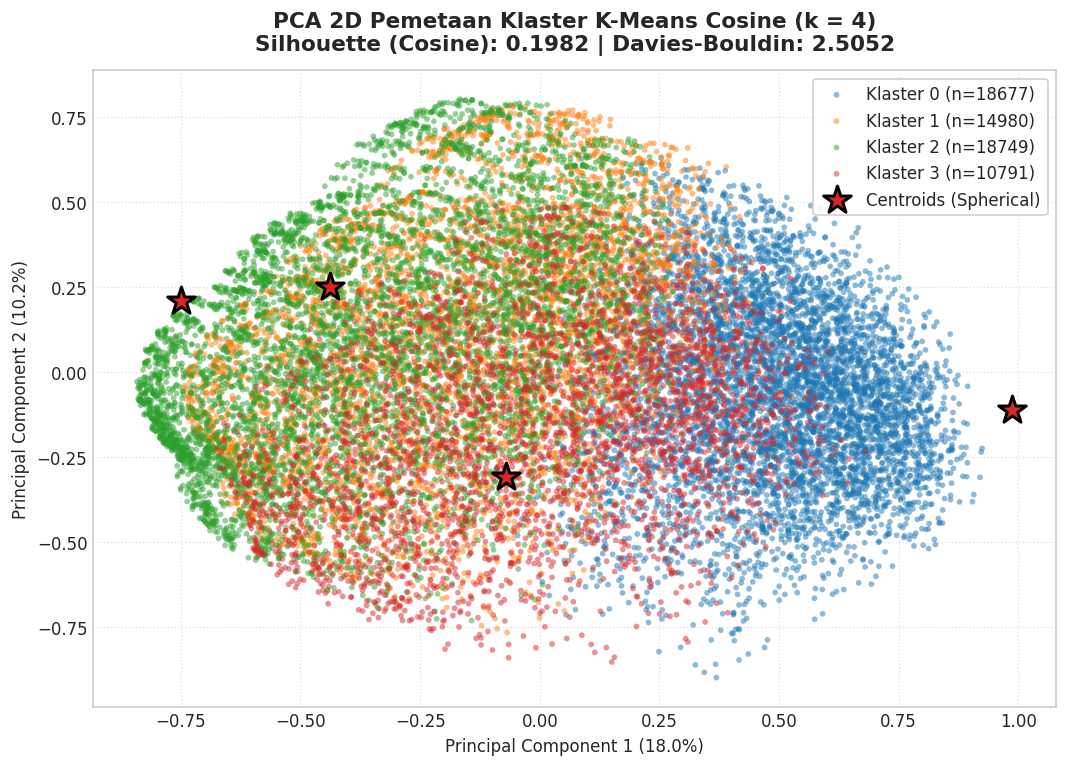

In [9]:
# Visualisasi
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_norm)
centroids_pca = pca.transform(model_cosine.centroids)

rng_plot = np.random.RandomState(RANDOM_STATE)
n_plot = min(20000, len(X_pca))
idx_plot = rng_plot.choice(len(X_pca), size=n_plot, replace=False)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab10", optimal_k)

for k in range(optimal_k):
    mask = (labels[idx_plot] == k)
    plt.scatter(
        X_pca[idx_plot][mask, 0], X_pca[idx_plot][mask, 1],
        color=palette[k],
        label=f'Klaster {k} (n={np.sum(labels == k)})',
        alpha=0.5, s=12, edgecolors='none'
    )

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='*', s=300, c='#DC2626',
    edgecolor='black', linewidth=1.8,
    label='Centroids (Spherical)', zorder=10
)

plt.title(f'PCA 2D Pemetaan Klaster K-Means Cosine (k = {optimal_k})\n'
          f'Silhouette (Cosine): {sil_score:.4f} | Davies-Bouldin: {db_score:.4f}',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_cosine.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SIMPAN] Grafik pemetaan klaster disimpan ke: '{cluster_path}'")
plt.show()

In [10]:
# Fitur paling berpengaruh
loadings = pd.DataFrame(pca.components_.T, index=df_features.columns, columns=['PC1', 'PC2'])  # bobot fitur di tiap PC
print("Fitur paling berpengaruh di PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))  # 6 teratas PC1
print("\nFitur paling berpengaruh di PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))  # 6 teratas PC2

Fitur paling berpengaruh di PC1:
GenHlth         0.428
DiffWalk        0.395
HighBP          0.371
PhysHlth        0.332
HighChol        0.294
PhysActivity    0.273
Name: PC1, dtype: float64

Fitur paling berpengaruh di PC2:
Age             0.470
Fruits          0.425
HighBP          0.399
HighChol        0.373
Veggies         0.288
PhysActivity    0.264
Name: PC2, dtype: float64


In [11]:
# ===== ARI & NMI vs label Diabetes_binary =====
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ALGO_NAME, METRIK_NAME = 'K-Means (spherical)', 'Cosine'

y_true = y_sample.values if 'y_sample' in globals() else y_label.values
lab = np.asarray(labels)
mk = lab != -1                                    # K-Means: semua True (tidak ada noise)

hasil_ext = pd.DataFrame([{
    'Algoritma': ALGO_NAME, 'Metrik': METRIK_NAME,
    'ARI (non-noise)':   round(adjusted_rand_score(y_true[mk], lab[mk]), 4),
    'NMI (non-noise)':   round(normalized_mutual_info_score(y_true[mk], lab[mk]), 4),
    'ARI (semua titik)': round(adjusted_rand_score(y_true, lab), 4),   # noise = 1 label (-1)
    'NMI (semua titik)': round(normalized_mutual_info_score(y_true, lab), 4),
}])
print(hasil_ext.to_string(index=False))

out = globals().get('OUTPUT_DIR', '.')
hasil_ext.to_excel(os.path.join(out, f'ari_nmi_{ALGO_NAME.lower()}_{METRIK_NAME.lower()}.xlsx'), index=False)

          Algoritma Metrik  ARI (non-noise)  NMI (non-noise)  ARI (semua titik)  NMI (semua titik)
K-Means (spherical) Cosine           0.0574           0.0497             0.0574             0.0497
